# 04 · Aprendizaje no supervisado — tipos de pozo
Cada pozo se representa por la **forma de su curva** en los primeros 12 meses (producción / pico), el tamaño del pico de petróleo y gas, y el GOR. Comprimimos con **SVD** y agrupamos con **K-Means**; comparamos con **DBSCAN**.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, polars as pl, duckdb
import matplotlib.pyplot as plt, seaborn as sns
from ypf_ds import config
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.figsize"] = (11, 4.5)
config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from ypf_ds.models.cluster import matriz_pozos, describir, MESES
import joblib
panel, pozos = pl.read_parquet(config.PANEL), pl.read_parquet(config.POZOS)
ids, M = matriz_pozos(panel, pozos)
Ms = StandardScaler().fit_transform(M)
print("Pozos:", len(ids), "| dimensiones:", M.shape[1])

Pozos: 4144 | dimensiones: 15


## SVD: ¿cuántas componentes?

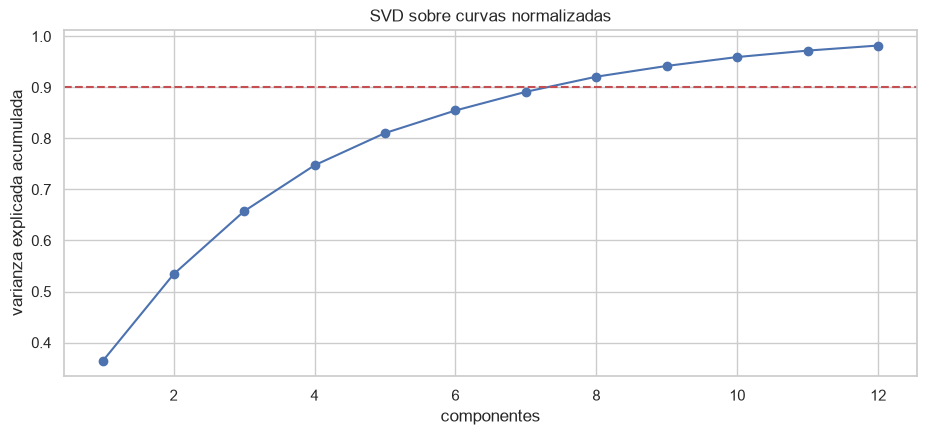

Varianza con 6 componentes: 0.855


In [3]:
svd = TruncatedSVD(n_components=12, random_state=42).fit(Ms)
var = np.cumsum(svd.explained_variance_ratio_)
plt.plot(range(1, 13), var, marker="o"); plt.axhline(.9, ls="--", c="r"); plt.xlabel("componentes"); plt.ylabel("varianza explicada acumulada")
plt.title("SVD sobre curvas normalizadas"); plt.savefig(config.DIR_FIGURAS / "04_svd.png", dpi=110); plt.show()
print("Varianza con 6 componentes:", round(var[5], 3))

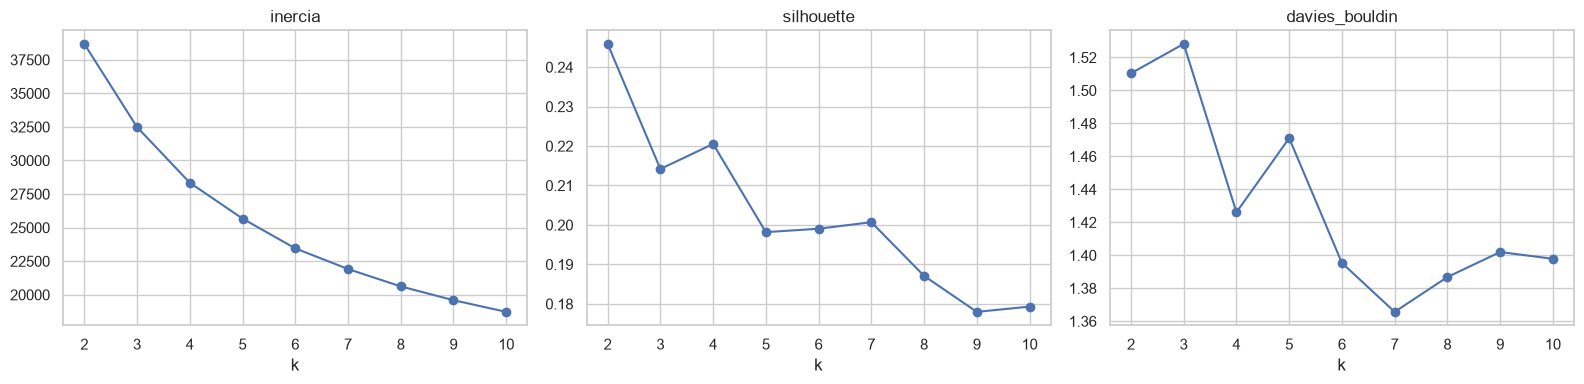

,inercia,silhouette,davies_bouldin
k,,,
2,38686.029,0.246,1.510
3,32487.421,0.214,1.528
4,28346.872,0.221,1.426
5,25673.585,0.198,1.471
6,23455.858,0.199,1.395
7,21917.578,0.201,1.366
8,20622.621,0.187,1.387
9,19594.998,0.178,1.402
10,18726.510,0.179,1.398


In [4]:
Z = TruncatedSVD(n_components=6, random_state=42).fit_transform(Ms)
res = []
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=42).fit(Z)
    res.append({"k": k, "inercia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_), "davies_bouldin": davies_bouldin_score(Z, km.labels_)})
res = pd.DataFrame(res).set_index("k")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, res.columns): res[c].plot(ax=a, marker="o", title=c)
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "04_codo_silhouette.png", dpi=110); plt.show(); res.round(3)

## DBSCAN
Elegimos `eps` con el gráfico de distancia al k-ésimo vecino (codo).

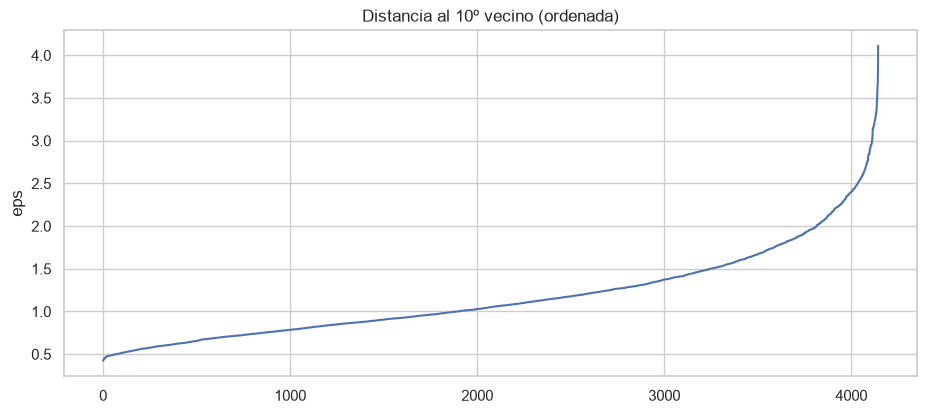

eps=0.6: clusters=3, ruido=84.4%, silhouette(sin ruido)=0.251
eps=0.9: clusters=3, ruido=48.0%, silhouette(sin ruido)=0.180
eps=1.2: clusters=3, ruido=23.4%, silhouette(sin ruido)=0.304


In [5]:
d = np.sort(NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)[0][:, -1])
plt.plot(d); plt.title("Distancia al 10º vecino (ordenada)"); plt.ylabel("eps"); plt.show()
for eps in [0.6, 0.9, 1.2]:
    lab = DBSCAN(eps=eps, min_samples=10).fit_predict(Z)
    n_c = len(set(lab)) - (-1 in lab); ruido = (lab == -1).mean()
    sil = silhouette_score(Z[lab != -1], lab[lab != -1]) if n_c > 1 else float("nan")
    print(f"eps={eps}: clusters={n_c}, ruido={ruido:.1%}, silhouette(sin ruido)={sil:.3f}")

DBSCAN marca como **ruido** entre el 23 % y el 84 % de los pozos según `eps`: las curvas de producción forman un **continuo** con densidad desigual, sin regiones densas bien separadas. Aunque su silhouette (calculado sin el ruido) puede ser algo mayor, no sirve para asignarle un tipo a *todos* los pozos, que es lo que necesita la API. K-Means agrupa el 100 % de los pozos en grupos interpretables, por eso es el elegido.

In [6]:
art = joblib.load(config.DIR_MODELOS / "clustering.joblib")
lab = np.array([art["asignacion"][i] for i in ids])
perfiles = pd.DataFrame(art["perfiles"]).set_index("cluster"); perfiles

,pozos,fluido,pico_pet_mediano_m3,pico_gas_mediano_Mm3,gor_mediano,retencion_mes12,nombre
cluster,,,,,,,
0,1621,Petróleo,3240.7,692.5,1.740000e+02,0.295,Petróleo · pico alto · declinación fuerte
1,1300,Petróleo,2130.4,1127.4,4.410000e+02,0.545,Petróleo · pico medio · declinación suave
2,529,Petróleo,154.7,463.1,1.447000e+03,0.144,Petróleo · pico bajo · declinación fuerte
3,694,Gas,0.0,4724.2,1.991156e+10,0.487,Gas · declinación suave


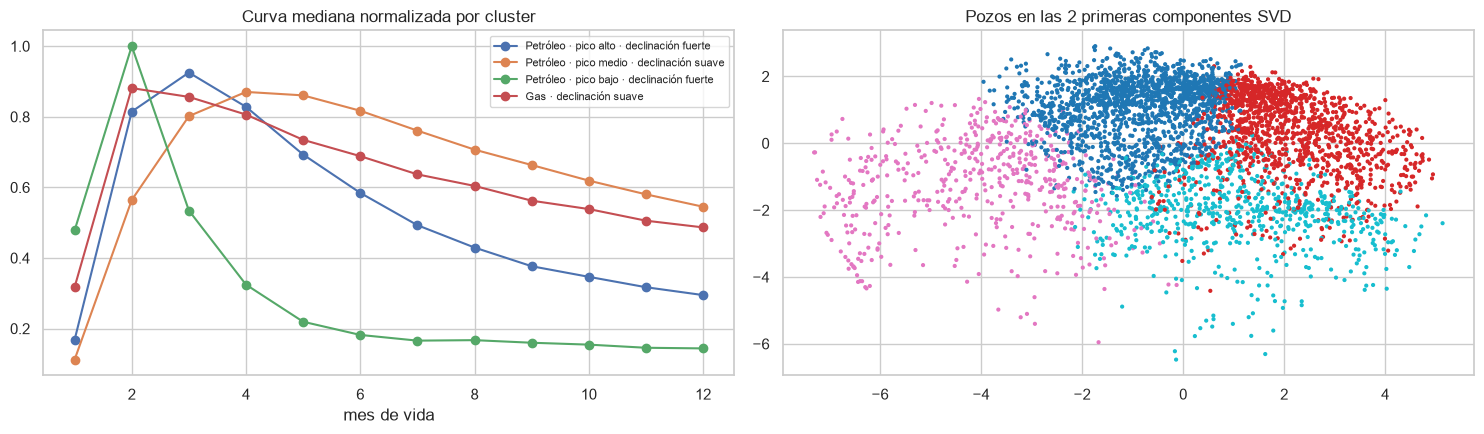

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for k in sorted(set(lab)):
    ax[0].plot(range(1, MESES + 1), np.median(M[lab == k, :MESES], axis=0), marker="o", label=perfiles.loc[k, "nombre"])
ax[0].set_title("Curva mediana normalizada por cluster"); ax[0].set_xlabel("mes de vida"); ax[0].legend(fontsize=8)
Z2 = TruncatedSVD(2, random_state=42).fit_transform(Ms)
ax[1].scatter(Z2[:, 0], Z2[:, 1], c=lab, s=4, cmap="tab10"); ax[1].set_title("Pozos en las 2 primeras componentes SVD")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "04_clusters.png", dpi=110); plt.show()

In [8]:
info = pozos.filter(pl.col("idpozo").is_in(ids.tolist())).to_pandas().set_index("idpozo").loc[ids]
info["cluster"] = lab
pd.crosstab(info.formacion, info.cluster).loc[lambda d: d.sum(axis=1) > 30]

cluster,0,1,2,3
formacion,,,,
agrio,2,3,11,41
lajas,89,159,79,241
los molles,56,39,51,29
mulichinco,59,80,35,55
precuyo,16,12,22,27
punta rosada,49,16,5,23
quintuco,22,14,35,8
vaca muerta,1322,968,285,261


Los clusters separan pozos de **petróleo vs gas** y, dentro de cada fluido, por **tamaño del pico** y **velocidad de declinación**. La API devuelve el cluster del pozo (o el que corresponde a la curva predicha de un pozo nuevo) como información técnica adicional.